# Semana 5 — Controle Fuzzy Adaptativo do Slime Mould Algorithm
### Controle dinâmico da taxa de reinicialização no Permutation Flow Shop

**Problema:** minimizar o Total Tardiness de sequências de trabalhos em máquinas de Flow Shop.  
**Métodos:** SMA com hiperparâmetros fixos (referência Optuna) e SMA com controlador Fuzzy Sugeno de ordem zero.  
**Instâncias:** `Ta001_2` (20 trabalhos, 5 máquinas) e `Ta041_3` (50 trabalhos, 10 máquinas).

O experimento investiga se a adaptação da probabilidade de reinicialização, orientada pelo estado da população, altera a qualidade das soluções. A avaliação exata e a representação por Random Keys permanecem idênticas nas duas variantes.

## 1. Objetivo e protocolo experimental

O controle adaptativo altera um parâmetro **durante a execução**, diferentemente da sintonia estática realizada com Optuna. O controlador observa a diversidade das permutações e a estagnação da melhor solução e determina a probabilidade `z` de reinicialização a cada geração.

| Item | Definição |
|:--|:--|
| Função objetivo | Total Tardiness, calculado pela `FlowShopEngine` |
| Representação | Random Keys decodificadas com `argsort` |
| Controlador | Sugeno de ordem zero, 2 entradas e 1 saída |
| Entradas | Diversidade das permutações e estagnação normalizada |
| Saída | Probabilidade de reinicialização `z_t` |
| Comparação | `SMA fixo` × `SMA Fuzzy` |
| Controle experimental | Mesmos parâmetros de população, mesmas instâncias, sementes e limite de avaliações reais |
| Avaliação | Média, desvio-padrão, melhor resultado, tempo, testes pareados e trajetória do parâmetro |

A comparação é realizada **sem o surrogate**, para identificar isoladamente o efeito do controlador Fuzzy. A integração com a MLP poderá ser investigada em um experimento subsequente.

In [1]:
import sys, subprocess, importlib.util, json, zipfile, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from IPython.display import display

# True: experimento de entrega; False: execução de verificação rápida.
EXECUCAO_COMPLETA = True
SEMENTE_GLOBAL = 2026
np.random.seed(SEMENTE_GLOBAL)
plt.rcParams.update({'figure.dpi':120, 'font.size':10, 'axes.grid':True, 'grid.alpha':0.18})
OUT = Path('/kaggle/working/semana5_fuzzy' if Path('/kaggle/working').exists() else '/mnt/data/semana5_fuzzy')
OUT.mkdir(parents=True, exist_ok=True)
CONFIG = {
    'avaliacoes': 3000 if EXECUCAO_COMPLETA else 200,
    'sementes': [401,503,607,709,811,907,1013,1109,1201,1303,1409,1511,1601,1709,1801,1907,2003,2111,2203,2309] if EXECUCAO_COMPLETA else [401,503],
    'janela_estagnacao': 12,
    'intensidade_controle': 1.0,
    'intervalo_z': (0.0, 0.15)
}
print('Modo:', 'EXPERIMENTO COMPLETO' if EXECUCAO_COMPLETA else 'VERIFICAÇÃO')
display(pd.DataFrame([{'configuração':k,'valor':str(v)} for k,v in CONFIG.items()]))
print('Arquivos:',OUT)

Modo: EXPERIMENTO COMPLETO


,configuração,valor
0,avaliacoes,3000
1,sementes,"[401, 503, 607, 709, 811, 907, 1013, 1109, 120..."
2,janela_estagnacao,12
3,intensidade_controle,1.0
4,intervalo_z,"(0.0, 0.15)"


Arquivos: /kaggle/working/semana5_fuzzy


## 2. Instâncias, função objetivo e configuração estática

A primeira linha das instâncias informa o número de trabalhos e máquinas. A segunda linha do arquivo não é utilizada no PFS adotado neste estudo. A função objetivo contabiliza o atraso positivo de cada trabalho, usando a mesma sequência de trabalhos em todas as máquinas.

\[
TT(\pi)=\sum_{j=1}^{n}\max(0,C_j(\pi)-d_j).
\]

Os hiperparâmetros fixos foram selecionados por Optuna na etapa anterior, com 50 trials para cada instância. Assim, o Fuzzy usa um valor de referência `z_base` já determinado, sem nova busca no conjunto de teste.

In [2]:
BASES = [Path('/kaggle/input/datasets/caiomoreiraban/dpfsp-dd/DPFSP_DD'),
         Path('/kaggle/input/dpfsp-dd/DPFSP_DD'),Path('/mnt/data/DPFSP_DD')]
DATASET_DIR = next((p for p in BASES if p.is_dir() and any(p.rglob('*.txt'))),None)
if DATASET_DIR is None and Path('/mnt/data/DPFSP_DD.zip').exists():
    with zipfile.ZipFile('/mnt/data/DPFSP_DD.zip') as zf:
        zf.extractall('/mnt/data')
    DATASET_DIR=Path('/mnt/data/DPFSP_DD')
if DATASET_DIR is None and Path('/kaggle/input').exists():
    for p in Path('/kaggle/input').rglob('Ta001_2.txt'):
        DATASET_DIR=next((q for q in p.parents if q.name=='DPFSP_DD'),p.parent)
        break
if DATASET_DIR is None:
    raise FileNotFoundError('Adicione o dataset DPFSP_DD em Input no Kaggle.')

class FlowShopEngine:
    def __init__(self,n_jobs,n_machines,proc_times,due_dates):
        self.n_jobs=n_jobs;self.n_machines=n_machines
        self.proc_times=np.asarray(proc_times,dtype=np.int32)
        self.due_dates=np.asarray(due_dates,dtype=np.int32)
        self.cfo_count=0

    @staticmethod
    def carregar_instancia_txt(caminho):
        with open(caminho,encoding='utf-8') as f:
            linhas=[linha.strip() for linha in f if linha.strip()]
        n,m=map(int,linhas[0].split())
        mat=np.zeros((n,m),dtype=np.int32)
        for j in range(n):
            pares=list(map(int,linhas[j+2].split()))
            if len(pares)!=2*m:raise ValueError(f'Formato inválido no trabalho {j}')
            maquinas=pares[::2];tempos=pares[1::2]
            if sorted(maquinas)!=list(range(m)):raise ValueError('Índices de máquinas inválidos')
            mat[j,maquinas]=tempos
        idx=next((i for i,s in enumerate(linhas) if s.lower()=='duedate'),None)
        if idx is None:raise ValueError('Campo Duedate ausente')
        due=np.asarray([int(v) for v in linhas[idx+1:idx+1+n]],dtype=np.int32)
        if len(due)!=n:raise ValueError('Prazos incompletos')
        return n,m,mat,due

    def bucket_sort_decode(self,keys):
        return np.argsort(np.asarray(keys)[:self.n_jobs],kind='stable')

    def evaluate_with_permutation(self,permutation,objective='Tardiness'):
        self.cfo_count+=1
        seq=np.asarray(permutation,dtype=int)
        if not np.array_equal(np.sort(seq),np.arange(self.n_jobs)):
            raise ValueError('Permutação inválida')
        term=np.zeros((self.n_machines,self.n_jobs),dtype=float)
        for maquina in range(self.n_machines):
            disponivel=0.
            for j in seq:
                disponivel=max(disponivel,term[maquina-1,j] if maquina>0 else 0.)+self.proc_times[j,maquina]
                term[maquina,j]=disponivel
        if objective=='Makespan':return float(term[-1].max())
        if objective=='Tardiness':return float(np.maximum(term[-1]-self.due_dates,0).sum())
        raise ValueError('Objetivo desconhecido')

    def evaluate(self,keys,mode='PFS',objective='Tardiness'):
        if mode!='PFS':raise ValueError('Somente PFS')
        return self.evaluate_with_permutation(self.bucket_sort_decode(keys),objective)

INSTANCIAS=['Large/Ta001_2.txt','Large/Ta041_3.txt']
PARAMETROS_SMA={
    'Large/Ta001_2.txt':{'populacao':40,'z':0.0008499388875837788},
    'Large/Ta041_3.txt':{'populacao':50,'z':0.13428290269269394}
}
ENGINES={nome:FlowShopEngine(*FlowShopEngine.carregar_instancia_txt(DATASET_DIR/nome)) for nome in INSTANCIAS}
linhas=[]
for nome,e in ENGINES.items():
    pars=PARAMETROS_SMA[nome]
    linhas.append({'instância':nome,'trabalhos':e.n_jobs,'máquinas':e.n_machines,**pars})
    keys=np.random.default_rng(1).random(e.n_jobs)
    assert e.evaluate(keys)==e.evaluate_with_permutation(e.bucket_sort_decode(keys))
display(pd.DataFrame(linhas).round(5))
print('Leitura e equivalência de avaliações: OK')

,instância,trabalhos,máquinas,populacao,z
0,Large/Ta001_2.txt,20,5,40,0.00085
1,Large/Ta041_3.txt,50,10,50,0.13428


Leitura e equivalência de avaliações: OK


## 3. Sistema de inferência Fuzzy

Foi adotado um controlador **Sugeno de ordem zero**. Cada regra possui um valor numérico constante como consequente. O resultado é a média ponderada dos consequentes pelas ativações das regras.

**Entradas em [0,1]:**

- **Diversidade (D):** média da distância de Hamming normalizada das permutações atuais em relação à melhor permutação da população. Valores baixos indicam sequências parecidas; valores altos indicam soluções diferentes.
- **Estagnação (E):** número de gerações consecutivas sem melhoria do melhor fitness, dividido pela janela de referência (12 gerações) e limitado a 1.

**Saída:** deslocamento `Δz` aplicado ao `z_base` selecionado pelo Optuna. `z_t = clip(z_base + Δz, 0, 0,15)`. A saída é recalculada **antes de gerar os novos indivíduos em cada geração**.

As funções de pertinência triangulares e trapezoidais definem as categorias linguísticas *baixa, média e alta* para cada entrada. As regras são hipóteses de controle formuladas para aumentar a exploração em situações de baixa diversidade e estagnação prolongada.

In [3]:
def triangular(x,a,b,c):
    x=np.asarray(x,dtype=float)
    return np.maximum(0.,np.minimum((x-a)/max(b-a,1e-12),(c-x)/max(c-b,1e-12)))

def trapezoidal(x,a,b,c,d):
    x=np.asarray(x,dtype=float)
    subida=np.where(x>=b,1.,(x-a)/max(b-a,1e-12))
    descida=np.where(x<=c,1.,(d-x)/max(d-c,1e-12))
    return np.clip(np.minimum(subida,descida),0.,1.)

def pertinencias(x):
    return {
        'Baixa':trapezoidal(x,0.,0.,0.20,0.50),
        'Média':triangular(x,0.20,0.50,0.80),
        'Alta':trapezoidal(x,0.50,0.80,1.,1.)
    }

# Consequentes de ordem zero: deslocamento de z em pontos de probabilidade.
# Linhas: diversidade, colunas: estagnação.
REGRAS=pd.DataFrame(
    [[0.000,0.030,0.065],
     [-0.020,0.000,0.040],
     [-0.040,-0.020,0.010]],
    index=['Baixa','Média','Alta'],columns=['Baixa','Média','Alta']
)

def controlador_fuzzy(diversidade,estagnacao,z_base,intensidade=1.):
    mu_d=pertinencias(np.clip(diversidade,0,1))
    mu_e=pertinencias(np.clip(estagnacao,0,1))
    pesos=[];valores=[]
    for div in REGRAS.index:
        for est in REGRAS.columns:
            ativacao=float(min(mu_d[div],mu_e[est]))
            pesos.append(ativacao)
            valores.append(float(REGRAS.loc[div,est]))
    soma=sum(pesos)
    delta=float(np.dot(pesos,valores)/soma) if soma>0 else 0.0
    return float(np.clip(z_base+intensidade*delta,*CONFIG['intervalo_z']))

print('Base de regras: Δz (probabilidade absoluta)')
display(REGRAS.rename_axis('Diversidade / Estagnação').style.format('{:+.3f}'))
assert 0<=controlador_fuzzy(.2,.9,.03)<=.15
assert controlador_fuzzy(.2,.9,.03)>controlador_fuzzy(.9,.1,.03)
print('Regras básicas verificadas.')

Base de regras: Δz (probabilidade absoluta)


,Baixa,Média,Alta
Diversidade / Estagnação,,,
Baixa,+0.000,+0.030,+0.065
Média,-0.020,+0.000,+0.040
Alta,-0.040,-0.020,+0.010


Regras básicas verificadas.


### 3.1. Funções de pertinência

Os gráficos mostram os graus de pertinência atribuídos a cada entrada. As sobreposições garantem transições graduais entre os termos linguísticos; as curvas não representam probabilidades e não precisam somar 1.

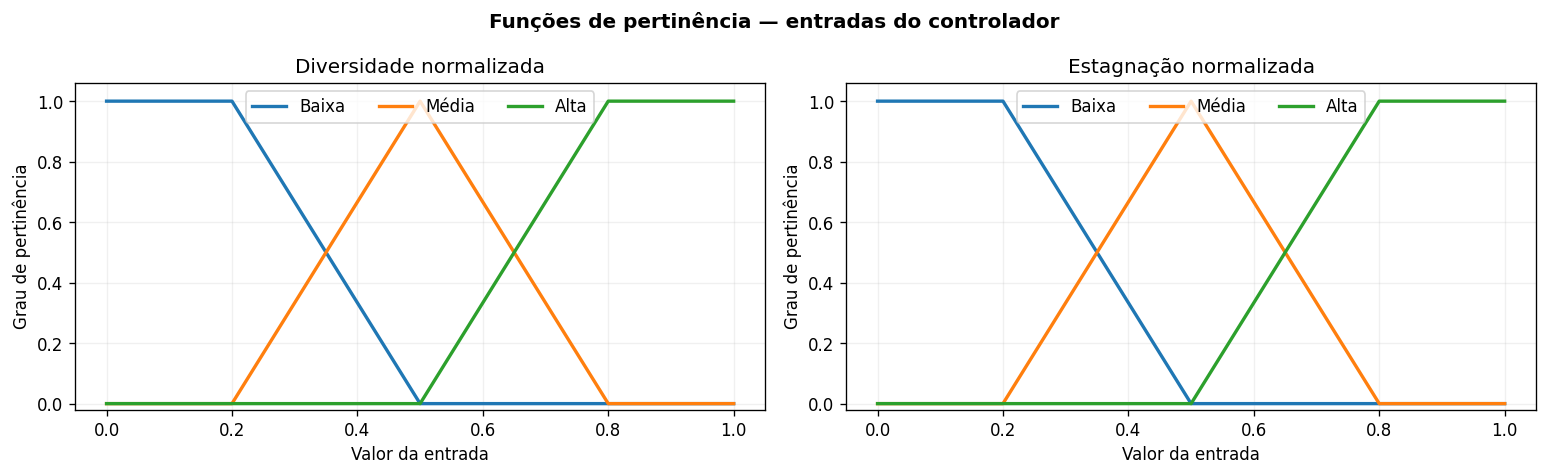

In [4]:
xx=np.linspace(0,1,501)
fig,axs=plt.subplots(1,2,figsize=(13,4))
for ax,titulo in zip(axs,['Diversidade normalizada','Estagnação normalizada']):
    for nome,v in pertinencias(xx).items():ax.plot(xx,v,label=nome,lw=2)
    ax.set(title=titulo,xlabel='Valor da entrada',ylabel='Grau de pertinência',ylim=(-.02,1.06))
    ax.legend(loc='upper center',ncol=3)
fig.suptitle('Funções de pertinência — entradas do controlador',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'01_funcoes_pertinencia.png',bbox_inches='tight');plt.show()

### 3.2. Superfície de controle

A superfície mostra a variação esperada de `z` para diferentes estados do SMA. O gráfico utiliza apenas o deslocamento `Δz`, antes do corte imposto ao intervalo permitido de `z`; assim, pode ser aplicado a ambas as instâncias, mesmo com valores de referência distintos.

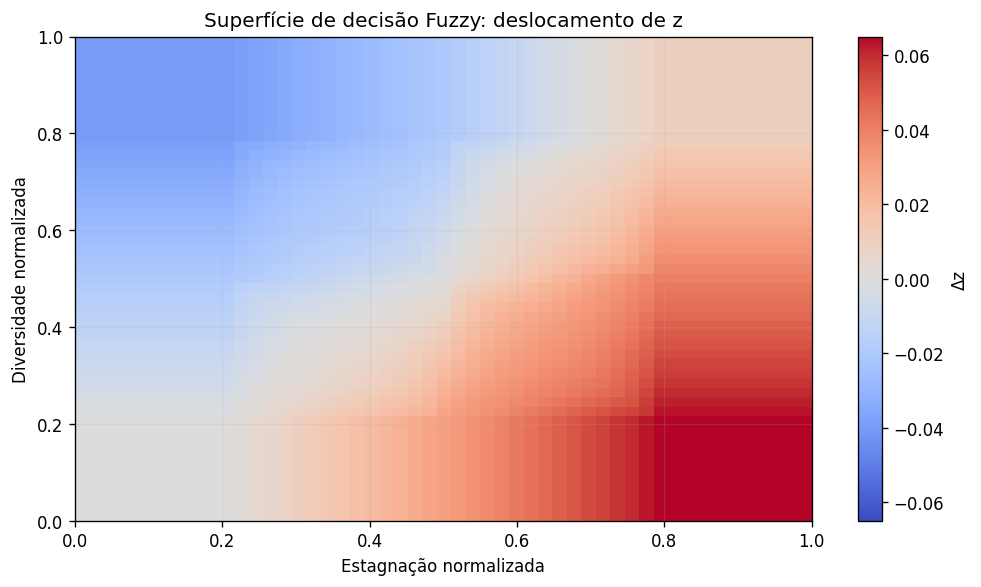

In [5]:
dv=np.linspace(0,1,51);ev=np.linspace(0,1,51)
surf=np.array([[controlador_fuzzy(d,e,0.) for e in ev] for d in dv])
# O ponto base zero e a restrição de não-negatividade ocultariam os deslocamentos negativos.
# Para mostrar a resposta completa, utiliza-se uma referência intermediária (0,075).
surf_delta=np.array([[controlador_fuzzy(d,e,.075)-.075 for e in ev] for d in dv])
fig,ax=plt.subplots(figsize=(8.5,5))
im=ax.imshow(surf_delta,origin='lower',aspect='auto',extent=[0,1,0,1],cmap='coolwarm',vmin=-.065,vmax=.065)
ax.set(xlabel='Estagnação normalizada',ylabel='Diversidade normalizada',title='Superfície de decisão Fuzzy: deslocamento de z')
cb=fig.colorbar(im,ax=ax);cb.set_label('Δz')
fig.tight_layout();fig.savefig(OUT/'02_superficie_controle.png',bbox_inches='tight');plt.show()

## 4. Integração do controlador ao SMA

A rotina a seguir conserva a atualização contínua e a decodificação empregadas no SMA anterior. Na versão fixa, `z_t = z_base`. Na versão adaptativa, o controlador é consultado a cada geração para calcular `z_t`, utilizando a diversidade e a estagnação da população **antes da atualização**.

Para comparabilidade, ambos os métodos utilizam o mesmo número de avaliações reais, o mesmo tamanho da população e as mesmas sementes. As trajetórias aleatórias deixam de coincidir após decisões diferentes de reinicialização, o que é esperado.

In [6]:
# Núcleo de execução do Slime Mould Algorithm (SMA) para minimização.
# A representação de permutação é definida pela função de avaliação externa.
def sma_otimizar(fo, dimensao, populacao=30, avaliacoes=3000, seed=42,
                 z=0.03, controlador=None, janela_estagnacao=12,
                 observador=None, seletor=None):
    """Executa o SMA e retorna melhor fitness, posição, histórico e diagnósticos.

    `controlador(diversidade, estagnacao, z_base)` devolve z da geração.
    `observador(keys, fitness, geracao)` recebe apenas avaliações exatas.
    `seletor(X, restantes)` devolve (fitness_previsto, indices_para_avaliar).
    Sem `seletor`, todos os indivíduos da geração são avaliados pela função objetivo.
    """
    pop, dim = int(populacao), int(dimensao)
    if pop < 3 or dim < 1 or int(avaliacoes) < pop or not 0 <= z <= 1:
        raise ValueError('Dimensões, orçamento ou parâmetros inválidos')
    budget = int(avaliacoes)
    rng = np.random.default_rng(seed)
    X = rng.uniform(0.0, 1.0, (pop, dim))
    melhor_x = np.zeros(dim, dtype=float)
    melhor_y = float('inf')
    usadas = 0
    geracao = 0
    melhor_geracao = 0
    linhas = []
    empate_geracional = []
    reinicios = 0
    if seletor is None:
        total_geracoes = int(np.ceil(budget / pop))
    else:
        lote_estimado = max(1, int(np.ceil(pop * 0.4)))
        total_geracoes = 1 + int(np.ceil((budget-pop) / lote_estimado))

    while usadas < budget:
        geracao += 1
        # Tratamento de limites do código de referência: aplicado antes da avaliação.
        np.clip(X, 0.0, 1.0, out=X)
        empate_geracional.append(float(np.mean([dim-len(np.unique(v)) for v in X])))
        restantes = budget - usadas
        if seletor is None or geracao == 1:
            indices_exatos = np.arange(min(pop, restantes), dtype=int)
            fitness = np.full(pop, np.inf, dtype=float)
        else:
            previstos, indices_exatos = seletor(X, restantes)
            fitness = np.asarray(previstos, dtype=float).copy()
            indices_exatos = np.asarray(indices_exatos, dtype=int)
            if fitness.shape != (pop,) or not np.all(np.isfinite(fitness)):
                raise ValueError('Predições de fitness inválidas')
            if len(indices_exatos) < 1 or len(indices_exatos) > restantes:
                raise ValueError('Quantidade inválida de avaliações exatas')

        for i in indices_exatos:
            fitness[i] = float(fo(X[i]))
            usadas += 1
            if not np.isfinite(fitness[i]):
                raise ValueError('Fitness não finito')
            if observador is not None:
                observador(X[i].copy(), float(fitness[i]), geracao-1)
            if float(fitness[i]) < melhor_y:
                melhor_y = float(fitness[i])
                melhor_x = X[i].copy()
                melhor_geracao = geracao
        if not np.isfinite(melhor_y):
            raise RuntimeError('Melhor fitness não identificado')

        # Entrada da política de controle: diferença média de posições nas permutações.
        diversidade = float(np.mean(np.argsort(X, axis=1, kind='stable') !=
                                   np.argsort(melhor_x, kind='stable')))
        estagnacao = float(min(1.0, max(0, geracao-melhor_geracao) /
                               max(1, int(janela_estagnacao))))
        z_atual = float(np.clip(controlador(diversidade, estagnacao, float(z))
                                 if controlador is not None else z, 0, 1))
        linhas.append(dict(geracao=geracao-1, avaliacoes=usadas,
                           melhor=melhor_y, diversidade=diversidade,
                           estagnacao=estagnacao, z=z_atual,
                           empates_medio=empate_geracional[-1]))
        if usadas >= budget:
            break

        # A ordem do ranking e a matriz de pesos seguem as operações da referência.
        ordem = np.argsort(fitness, kind='stable')
        melhor_atual = float(fitness[ordem[0]])
        pior_atual = float(fitness[ordem[-1]])
        denominador = melhor_atual - pior_atual + np.finfo(float).eps
        W = np.ones_like(X)
        for pos, idx in enumerate(ordem):
            razao = (melhor_atual - float(fitness[idx])) / denominador if melhor_atual != pior_atual else 0.0
            termo = float(np.log10(razao + 1.0))
            sinal = 1.0 if pos + 1 <= pop/2 else -1.0
            for j in range(dim):
                W[idx, j] = 1.0 + sinal * rng.random() * termo

        a = float(np.arctanh(1.0 - geracao / total_geracoes))
        b = float(1.0 - geracao / total_geracoes)
        # Atualização sequencial, usando a mesma matriz de posições.
        for i in range(pop):
            if rng.random() < z_atual:
                X[i, :] = rng.random()  # reinicialização por escalar
                reinicios += 1
            else:
                p = float(np.tanh(abs(float(fitness[i]) - melhor_y)))
                vb = rng.uniform(-a, a, size=dim)
                vc = rng.uniform(-b, b, size=dim)
                for j in range(dim):
                    r = rng.random()
                    A = int(rng.integers(0, pop))
                    B = int(rng.integers(0, pop))
                    if r < p:
                        X[i, j] = melhor_x[j] + vb[j] * (W[i, j] * X[A, j] - X[B, j])
                    else:
                        X[i, j] = vc[j] * X[i, j]
    historico_df = pd.DataFrame(linhas)
    historico = historico_df[['avaliacoes', 'melhor']].to_numpy(dtype=float)
    return dict(fitness=melhor_y, melhor_posicao=melhor_x,
                historico=historico, historico_completo=historico_df,
                cfo=usadas, empates_medio=float(np.mean(empate_geracional)),
                reinicios=reinicios)



def diversidade_permutacoes(X,melhor_x):
    return float(np.mean(np.argsort(X,axis=1,kind='stable')!=np.argsort(melhor_x,kind='stable')))

def executar_sma_controle(engine,parametros,seed,budget,adaptativo=False,
                           escala_positiva=1.,escala_negativa=1.,janela_estagnacao=None):
    z_base=float(parametros['z'])
    janela=int(janela_estagnacao or CONFIG['janela_estagnacao'])
    def politica(d,e,z):
        if not adaptativo:
            return z
        # Com assinatura de quatro argumentos, a versão com Optuna passa as escalas.
        try:
            return controlador_fuzzy(d,e,z,escala_positiva,escala_negativa)
        except TypeError:
            return controlador_fuzzy(d,e,z,CONFIG.get('intensidade_controle',1.))
    r=sma_otimizar(lambda x:engine.evaluate(x,mode='PFS',objective='Tardiness'),
                   engine.n_jobs,populacao=int(parametros['populacao']),
                   avaliacoes=budget,seed=seed,z=z_base,
                   controlador=politica if adaptativo else None,
                   janela_estagnacao=janela)
    return {'fitness':r['fitness'], 'permutacao':engine.bucket_sort_decode(r['melhor_posicao']),
            'cfo':r['cfo'], 'historico':r['historico_completo']}

for nome,engine in ENGINES.items():
    for adaptativo in (False,True):
        cfg=PARAMETROS_SMA[nome];test_budget=max(120,int(cfg['populacao'])*3)
        r=executar_sma_controle(engine,cfg,12345,test_budget,adaptativo)
        assert r['cfo']==test_budget
        assert np.array_equal(np.sort(r['permutacao']),np.arange(engine.n_jobs))
        assert r['historico']['melhor'].diff().dropna().le(0).all()
        assert r['historico']['z'].between(*CONFIG['intervalo_z']).all()
print('Verificação do solver e do controlador: OK')


Verificação do solver e do controlador: OK


## 5. Execução experimental

São realizadas execuções independentes com as sementes indicadas no protocolo. O número de avaliações reais (`CFO`) é fixo. Os dados armazenados incluem fitness final, tempo, permutação, trajetória da melhor solução, diversidade, estagnação e parâmetro ajustado.

In [7]:
REGISTROS=[];HISTORICOS=[]
for nome,engine in ENGINES.items():
    print(f'\nInstância: {nome} — {engine.n_jobs} trabalhos, {engine.n_machines} máquinas')
    for seed in CONFIG['sementes']:
        for metodo,flag in [('SMA fixo',False),('SMA Fuzzy',True)]:
            t0=time.perf_counter()
            res=executar_sma_controle(engine,PARAMETROS_SMA[nome],seed,CONFIG['avaliacoes'],flag)
            tempo=time.perf_counter()-t0
            REGISTROS.append({'instancia':nome,'metodo':metodo,'semente':seed,
                              'total_tardiness':res['fitness'],'tempo_s':tempo,'avaliacoes':res['cfo'],
                              'permutacao':','.join(map(str,res['permutacao']))})
            h=res['historico'].copy()
            h['instancia']=nome;h['metodo']=metodo;h['semente']=seed
            HISTORICOS.append(h)
        if not EXECUCAO_COMPLETA:print(f'  Semente {seed} concluída')
    print('  Execuções concluídas:',2*len(CONFIG['sementes']))
EXECUCOES=pd.DataFrame(REGISTROS)
HIST=pd.concat(HISTORICOS,ignore_index=True)
EXECUCOES.to_csv(OUT/'execucoes_individuais.csv',index=False)
HIST.to_csv(OUT/'trajetorias_geracionais.csv',index=False)
print('\nResumo inicial:')
display(EXECUCOES.groupby(['instancia','metodo'])[['total_tardiness','tempo_s','avaliacoes']].mean().round(3))


Instância: Large/Ta001_2.txt — 20 trabalhos, 5 máquinas
  Execuções concluídas: 40

Instância: Large/Ta041_3.txt — 50 trabalhos, 10 máquinas
  Execuções concluídas: 40

Resumo inicial:


total_tardiness  tempo_s  avaliacoes
instancia         metodo                                         
Large/Ta001_2.txt SMA Fuzzy          6852.35    0.730      3000.0
                  SMA fixo           6916.10    0.721      3000.0
Large/Ta041_3.txt SMA Fuzzy         53370.50    2.088      3000.0
                  SMA fixo          53565.95    2.048      3000.0

## 6. Evolução temporal do controle adaptativo

As figuras seguintes mostram, em cada instância, a trajetória de `z` durante uma execução representativa e os estados que justificam sua atualização. A linha tracejada representa o valor estático obtido pelo Optuna.

**Interpretação:** aumento de `z` indica uma resposta de maior exploração; redução de `z` indica menor probabilidade de reinicialização. O gráfico também permite confirmar que o controlador foi consultado a cada geração, como exigido no protocolo.

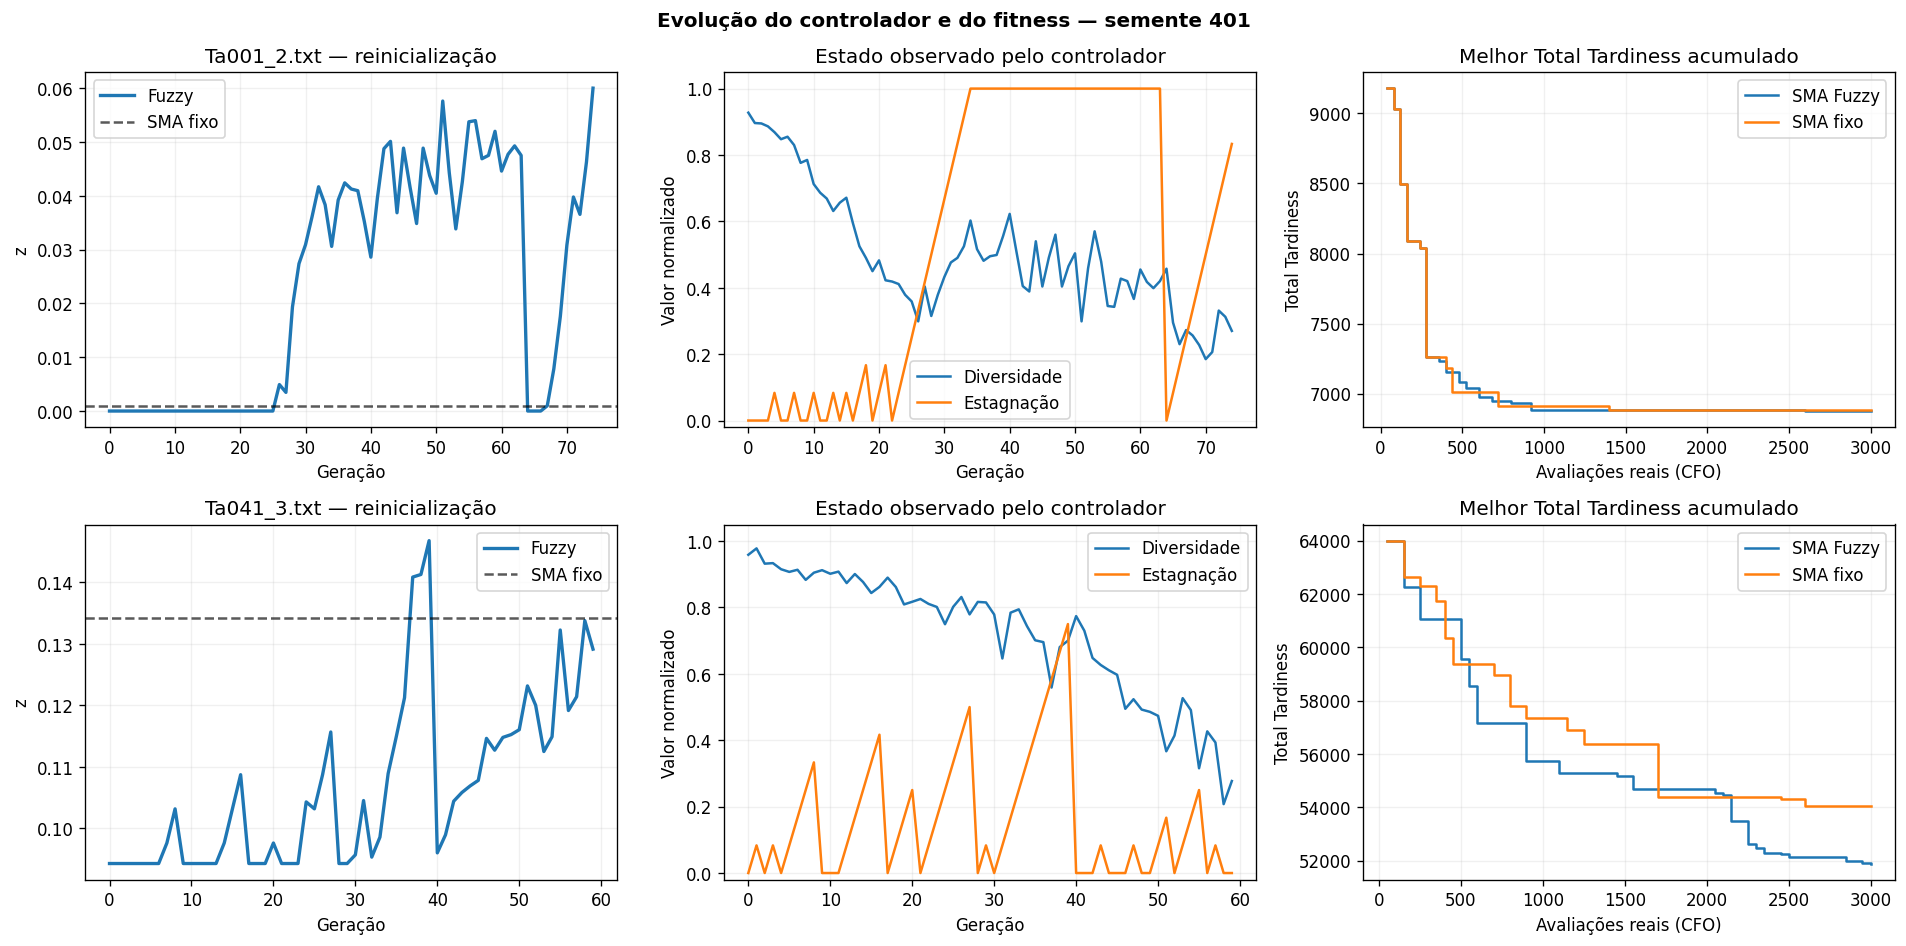

In [8]:
seed=CONFIG['sementes'][0]
fig,axs=plt.subplots(2,3,figsize=(16,8))
for linha,nome in enumerate(INSTANCIAS):
    h=HIST[(HIST.instancia==nome)&(HIST.metodo=='SMA Fuzzy')&(HIST.semente==seed)]
    hf=HIST[(HIST.instancia==nome)&(HIST.metodo=='SMA fixo')&(HIST.semente==seed)]
    axs[linha,0].plot(h.geracao,h.z,label='Fuzzy',lw=2)
    axs[linha,0].axhline(PARAMETROS_SMA[nome]['z'],ls='--',color='black',alpha=.65,label='SMA fixo')
    axs[linha,0].set(title=f'{nome.split("/")[-1]} — reinicialização',xlabel='Geração',ylabel='z');axs[linha,0].legend()
    axs[linha,1].plot(h.geracao,h.diversidade,label='Diversidade')
    axs[linha,1].plot(h.geracao,h.estagnacao,label='Estagnação')
    axs[linha,1].set(title='Estado observado pelo controlador',xlabel='Geração',ylabel='Valor normalizado',ylim=(-.02,1.05));axs[linha,1].legend()
    axs[linha,2].step(h.avaliacoes,h.melhor,where='post',label='SMA Fuzzy')
    axs[linha,2].step(hf.avaliacoes,hf.melhor,where='post',label='SMA fixo')
    axs[linha,2].set(title='Melhor Total Tardiness acumulado',xlabel='Avaliações reais (CFO)',ylabel='Total Tardiness');axs[linha,2].legend()
fig.suptitle(f'Evolução do controlador e do fitness — semente {seed}',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'03_evolucao_fuzzy.png',bbox_inches='tight');plt.show()

### 6.1. Distribuição dos valores de `z` e sensibilidade à instância

A distribuição agrega todas as execuções do SMA Fuzzy. Como `z_base` e o comportamento da população variam entre as instâncias, a amplitude observada pode ser diferente mesmo com as mesmas regras.

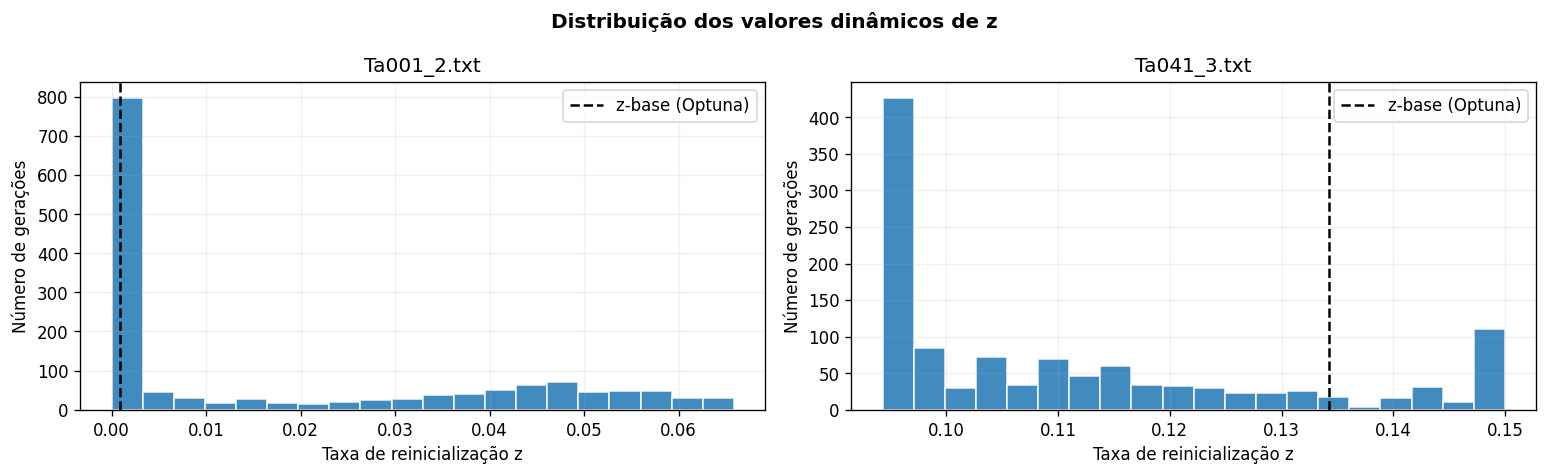

In [9]:
fig,axs=plt.subplots(1,2,figsize=(13,4))
for ax,nome in zip(axs,INSTANCIAS):
    hs=HIST[(HIST.instancia==nome)&(HIST.metodo=='SMA Fuzzy')&(HIST.geracao>0)]
    ax.hist(hs.z,bins=20,edgecolor='white',alpha=.85)
    ax.axvline(PARAMETROS_SMA[nome]['z'],ls='--',color='black',label='z-base (Optuna)')
    ax.set(title=nome.split('/')[-1],xlabel='Taxa de reinicialização z',ylabel='Número de gerações')
    ax.legend()
fig.suptitle('Distribuição dos valores dinâmicos de z',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'04_distribuicao_z.png',bbox_inches='tight');plt.show()

## 7. Comparação de qualidade e custo computacional

O desempenho é avaliado com o mesmo número de avaliações reais por execução. As médias são comparadas **dentro de cada instância**, pois os valores absolutos do Total Tardiness não têm a mesma escala entre problemas diferentes.

\[
\mathrm{Ganho}_{\%}=100

rac{\overline{TT}_{fixo}-\overline{TT}_{Fuzzy}}{\overline{TT}_{fixo}}.
\]

Ganhos positivos indicam menor atraso médio para a versão adaptativa. Tempos maiores indicam custo adicional do controlador.

In [10]:
RESUMO=EXECUCOES.groupby(['instancia','metodo']).agg(
    media=('total_tardiness','mean'),desvio=('total_tardiness','std'),
    melhor=('total_tardiness','min'),pior=('total_tardiness','max'),
    tempo_medio_s=('tempo_s','mean'),cfo=('avaliacoes','mean')).reset_index()
RESUMO['desvio']=RESUMO['desvio'].fillna(0.)
comparacao=[]
for nome in INSTANCIAS:
    a=RESUMO[(RESUMO.instancia==nome)&(RESUMO.metodo=='SMA fixo')].iloc[0]
    b=RESUMO[(RESUMO.instancia==nome)&(RESUMO.metodo=='SMA Fuzzy')].iloc[0]
    comparacao.append({'instancia':nome,'media_fixo':a.media,'media_fuzzy':b.media,
        'ganho_pct':100*(a.media-b.media)/a.media if a.media!=0 else np.nan,
        'tempo_fixo_s':a.tempo_medio_s,'tempo_fuzzy_s':b.tempo_medio_s,
        'sobrecusto_tempo_pct':100*(b.tempo_medio_s/a.tempo_medio_s-1)})
COMPARACAO=pd.DataFrame(comparacao)
RESUMO.to_csv(OUT/'resumo_completo.csv',index=False)
COMPARACAO.to_csv(OUT/'comparacao_fixo_fuzzy.csv',index=False)
print('Resultados por instância e método:')
display(RESUMO.round(3))
print('Diferenças relativas e custo:')
display(COMPARACAO.round(3))

Resultados por instância e método:


,instancia,metodo,media,desvio,melhor,pior,tempo_medio_s,cfo
0,Large/Ta001_2.txt,SMA Fuzzy,6852.35,148.413,6645.0,7129.0,0.730,3000.0
1,Large/Ta001_2.txt,SMA fixo,6916.10,167.582,6716.0,7336.0,0.721,3000.0
2,Large/Ta041_3.txt,SMA Fuzzy,53370.50,1704.214,50381.0,58416.0,2.088,3000.0
3,Large/Ta041_3.txt,SMA fixo,53565.95,1134.259,51422.0,55691.0,2.048,3000.0


Diferenças relativas e custo:


,instancia,media_fixo,media_fuzzy,ganho_pct,tempo_fixo_s,tempo_fuzzy_s,sobrecusto_tempo_pct
0,Large/Ta001_2.txt,6916.10,6852.35,0.922,0.721,0.730,1.315
1,Large/Ta041_3.txt,53565.95,53370.50,0.365,2.048,2.088,1.989


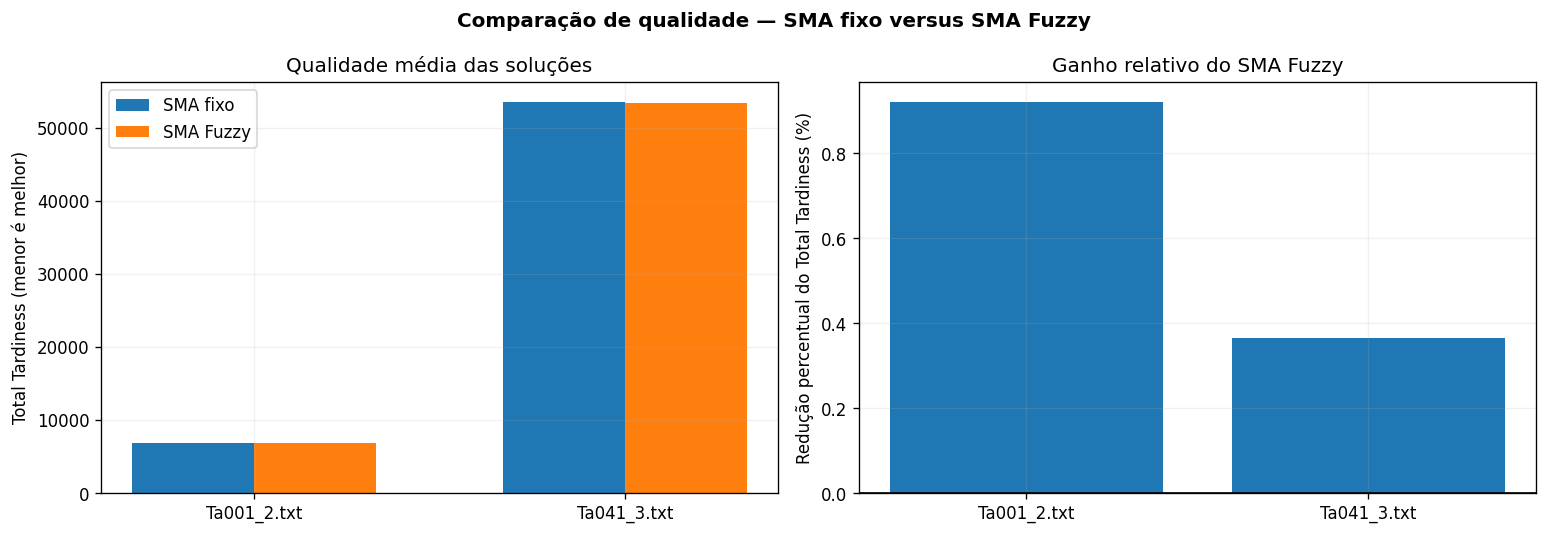

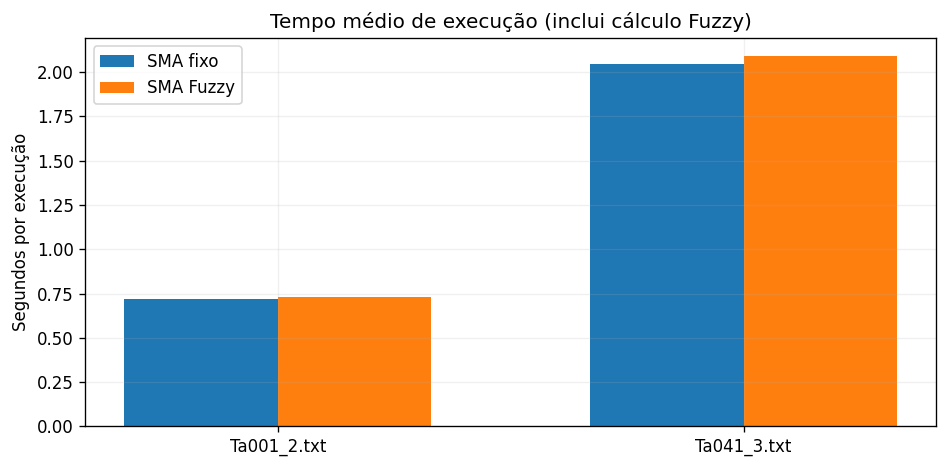

In [11]:
fig,axs=plt.subplots(1,2,figsize=(13,4.5))
nomes=[x.split('/')[-1] for x in INSTANCIAS];x=np.arange(len(nomes));larg=.33
for k,met in enumerate(['SMA fixo','SMA Fuzzy']):
    aux=RESUMO[RESUMO.metodo==met].set_index('instancia').loc[INSTANCIAS]
    axs[0].bar(x+(k-.5)*larg,aux.media,width=larg,label=met)
axs[0].set(xticks=x,xticklabels=nomes,title='Qualidade média das soluções',ylabel='Total Tardiness (menor é melhor)');axs[0].legend()
axs[1].bar(nomes,COMPARACAO.ganho_pct)
axs[1].axhline(0,color='black',lw=1)
axs[1].set(title='Ganho relativo do SMA Fuzzy',ylabel='Redução percentual do Total Tardiness (%)')
fig.suptitle('Comparação de qualidade — SMA fixo versus SMA Fuzzy',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'05_qualidade_solucoes.png',bbox_inches='tight');plt.show()
fig,ax=plt.subplots(figsize=(8,4))
for k,met in enumerate(['SMA fixo','SMA Fuzzy']):
    aux=RESUMO[RESUMO.metodo==met].set_index('instancia').loc[INSTANCIAS]
    ax.bar(x+(k-.5)*larg,aux.tempo_medio_s,width=larg,label=met)
ax.set(xticks=x,xticklabels=nomes,title='Tempo médio de execução (inclui cálculo Fuzzy)',ylabel='Segundos por execução')
ax.legend();fig.tight_layout();fig.savefig(OUT/'06_tempo_execucao.png',bbox_inches='tight');plt.show()

### 7.1. Variabilidade entre sementes

O boxplot apresenta a distribuição do fitness final. Caixas mais baixas e concentradas indicam melhor qualidade e menor dispersão. O gráfico deve ser interpretado em conjunto com a média e o desvio-padrão, especialmente em instâncias com poucos resultados distintos.

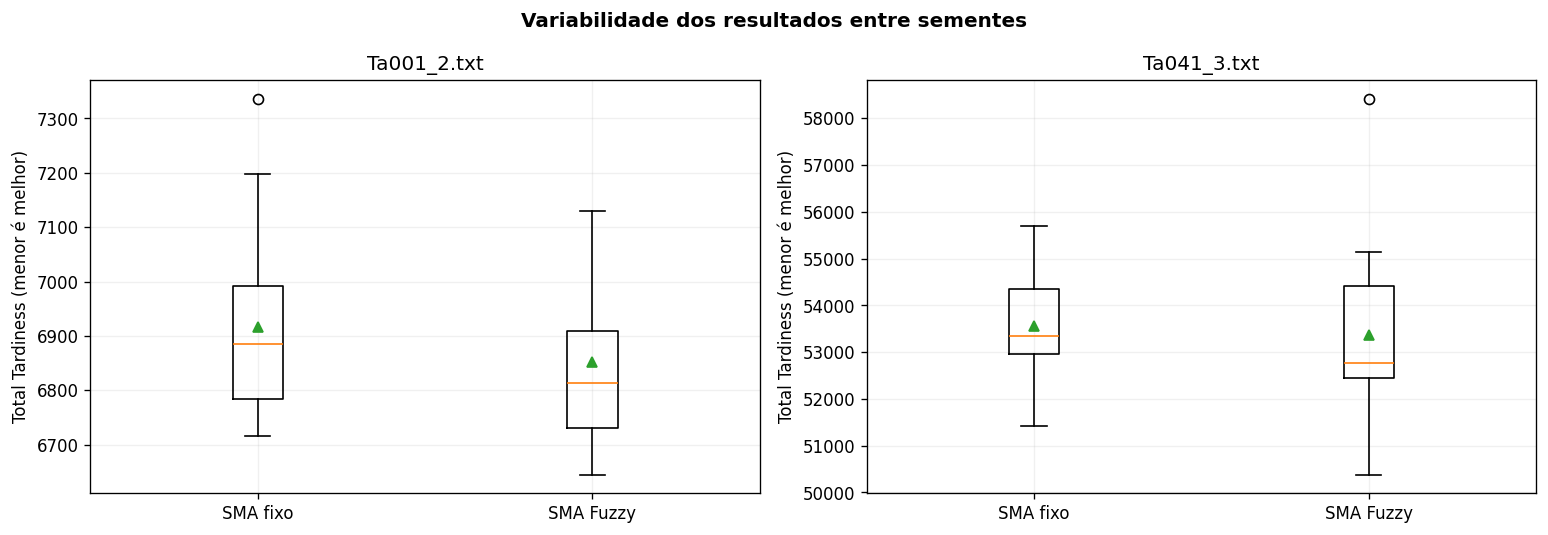

In [12]:
fig,axs=plt.subplots(1,2,figsize=(13,4.5))
for ax,nome in zip(axs,INSTANCIAS):
    vals=[EXECUCOES[(EXECUCOES.instancia==nome)&(EXECUCOES.metodo==met)].total_tardiness.values
          for met in ['SMA fixo','SMA Fuzzy']]
    ax.boxplot(vals,tick_labels=['SMA fixo','SMA Fuzzy'],showmeans=True)
    ax.set(title=nome.split('/')[-1],ylabel='Total Tardiness (menor é melhor)')
fig.suptitle('Variabilidade dos resultados entre sementes',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'07_boxplots.png',bbox_inches='tight');plt.show()

## 8. Análise estatística pareada

As mesmas sementes são utilizadas nos dois métodos. O teste de Wilcoxon de duas caudas é aplicado às diferenças de fitness final, com a hipótese nula de diferença central igual a zero. O número de pares é informado; significância estatística não deve ser confundida com relevância prática.

As medições de tempo são informadas descritivamente, pois sua variação também depende do ambiente de execução.

In [13]:
ESTATISTICAS=[]
for nome in INSTANCIAS:
    pivot=EXECUCOES[EXECUCOES.instancia==nome].pivot(index='semente',columns='metodo',values='total_tardiness')
    dif=(pivot['SMA fixo']-pivot['SMA Fuzzy']).to_numpy()
    if len(dif)>=6 and np.any(dif!=0):
        p=float(wilcoxon(dif,alternative='two-sided',zero_method='wilcox').pvalue)
    else:p=np.nan
    ESTATISTICAS.append({'instancia':nome,'pares':len(dif),'vitorias_fuzzy':int((dif>0).sum()),
        'empates':int((dif==0).sum()),'vitorias_fixo':int((dif<0).sum()),
        'diferenca_media_fixo_menos_fuzzy':float(dif.mean()),'wilcoxon_p_bilateral':p})
ESTATISTICAS=pd.DataFrame(ESTATISTICAS)
ESTATISTICAS.to_csv(OUT/'testes_estatisticos.csv',index=False)
display(ESTATISTICAS.round(5))

,instancia,pares,vitorias_fuzzy,empates,vitorias_fixo,diferenca_media_fixo_menos_fuzzy,wilcoxon_p_bilateral
0,Large/Ta001_2.txt,20,13,0,7,63.75,0.19771
1,Large/Ta041_3.txt,20,12,0,8,195.45,0.43043


## 9. Discussão e conclusão experimental

Esta seção sintetiza automaticamente as diferenças calculadas, sem antecipar superioridade de qualquer método. A qualidade, o custo computacional e o comportamento temporal do controlador são analisados separadamente.

In [14]:
for nome in INSTANCIAS:
    r=COMPARACAO[COMPARACAO.instancia==nome].iloc[0]
    es=ESTATISTICAS[ESTATISTICAS.instancia==nome].iloc[0]
    hs=HIST[(HIST.instancia==nome)&(HIST.metodo=='SMA Fuzzy')&(HIST.geracao>0)]
    print('\n'+'='*72)
    print('INSTÂNCIA:',nome)
    print('Configuração Optuna:',PARAMETROS_SMA[nome])
    print(f'Qualidade: SMA fixo={r.media_fixo:,.2f}; SMA Fuzzy={r.media_fuzzy:,.2f}.')
    print(f'Ganho relativo do Fuzzy: {r.ganho_pct:+.3f}% (positivo = melhor).')
    print(f'Tempos médios: fixo={r.tempo_fixo_s:.4f} s; Fuzzy={r.tempo_fuzzy_s:.4f} s; sobrecusto={r.sobrecusto_tempo_pct:+.2f}%.')
    print(f'Variação observada de z: mínimo={hs.z.min():.4f}, médio={hs.z.mean():.4f}, máximo={hs.z.max():.4f}.')
    print(f'Vitórias por semente: Fuzzy={int(es.vitorias_fuzzy)}, fixo={int(es.vitorias_fixo)}, empates={int(es.empates)}.')
    if np.isfinite(es.wilcoxon_p_bilateral):
        print(f'Wilcoxon bilateral: p={es.wilcoxon_p_bilateral:.5f}; ' +
              ('diferença detectada a 5%.' if es.wilcoxon_p_bilateral<0.05 else 'diferença não detectada a 5%.'))
    else:print('Amostra reduzida ou diferenças nulas: Wilcoxon não aplicado.')
    print('Interpretação:', 'o controlador reduziu o atraso médio.' if r.ganho_pct>0 else
          'não houve redução do atraso médio nesta instância.')
print('\nLIMITAÇÕES: duas instâncias; regras fixadas antes da avaliação; controle aplicado somente ao z;')
print('a relação custo-benefício depende da implementação e do orçamento de avaliações reais.')


INSTÂNCIA: Large/Ta001_2.txt
Configuração Optuna: {'populacao': 40, 'z': 0.0008499388875837788}
Qualidade: SMA fixo=6,916.10; SMA Fuzzy=6,852.35.
Ganho relativo do Fuzzy: +0.922% (positivo = melhor).
Tempos médios: fixo=0.7206 s; Fuzzy=0.7301 s; sobrecusto=+1.31%.
Variação observada de z: mínimo=0.0000, médio=0.0177, máximo=0.0658.
Vitórias por semente: Fuzzy=13, fixo=7, empates=0.
Wilcoxon bilateral: p=0.19771; diferença não detectada a 5%.
Interpretação: o controlador reduziu o atraso médio.

INSTÂNCIA: Large/Ta041_3.txt
Configuração Optuna: {'populacao': 50, 'z': 0.13428290269269394}
Qualidade: SMA fixo=53,565.95; SMA Fuzzy=53,370.50.
Ganho relativo do Fuzzy: +0.365% (positivo = melhor).
Tempos médios: fixo=2.0476 s; Fuzzy=2.0883 s; sobrecusto=+1.99%.
Variação observada de z: mínimo=0.0943, médio=0.1109, máximo=0.1500.
Vitórias por semente: Fuzzy=12, fixo=8, empates=0.
Wilcoxon bilateral: p=0.43043; diferença não detectada a 5%.
Interpretação: o controlador reduziu o atraso médio.


## 10. Arquivos e reprodutibilidade

Os gráficos são exibidos no notebook e salvos como arquivos PNG. As tabelas de execuções, trajetórias do controlador e análises estatísticas são exportadas em CSV. Um manifesto JSON registra as instâncias, as sementes, os parâmetros fixos e as regras Fuzzy.

**Arquivos principais:** `execucoes_individuais.csv`, `trajetorias_geracionais.csv`, `comparacao_fixo_fuzzy.csv`, `testes_estatisticos.csv` e os gráficos `01` a `07`.

In [15]:
MANIFESTO={
    'titulo':'Semana 5 — Controle Fuzzy Adaptativo do SMA',
    'formulacao':'Permutation Flow Shop, minimização do Total Tardiness',
    'instancias':INSTANCIAS,
    'optuna_semana4':PARAMETROS_SMA,
    'config':CONFIG,
    'entradas':['diversidade de permutações','estagnação em gerações'],
    'saida':'z_t: probabilidade de reinicialização por geração',
    'inferência':'Sugeno ordem zero; AND=min; agregação=média ponderada',
    'base_regras':REGRAS.to_dict(),
    'observacao':'Avaliador exato preservado; surrogate não utilizado na comparação isolada.'
}
with open(OUT/'manifesto.json','w',encoding='utf-8') as f:
    json.dump(MANIFESTO,f,indent=2,ensure_ascii=False)
print('Resultados salvos em:',OUT)
for arq in sorted(OUT.iterdir()):
    if arq.is_file():print(' •',arq.name)

Resultados salvos em: /kaggle/working/semana5_fuzzy
 • 01_funcoes_pertinencia.png
 • 02_superficie_controle.png
 • 03_evolucao_fuzzy.png
 • 04_distribuicao_z.png
 • 05_qualidade_solucoes.png
 • 06_tempo_execucao.png
 • 07_boxplots.png
 • comparacao_fixo_fuzzy.csv
 • execucoes_individuais.csv
 • manifesto.json
 • resumo_completo.csv
 • testes_estatisticos.csv
 • trajetorias_geracionais.csv
